# 🚗 Used Car Price Prediction

**Zero Grad · Machine Learning course · Project 1**

A used-car website wants to show sellers a fair price for their car.
We build a regression model that predicts the **price** of a used car in India from its details
(brand, model, year, kilometers, engine, power, ...), and ship it as a **Streamlit app**.

**Data:** [Used Cars Price Prediction](https://www.kaggle.com/datasets/avikasliwal/used-cars-price-prediction) on Kaggle:
6,019 cars listed up to 2019. `Price` is in **lakh** (1 lakh = ₹100,000).

| # | Step | From the course |
|---|---|---|
| 1 | Diagnose the raw data | Data Preprocessing 01 |
| 2 | Clean it | Data Preprocessing 02 |
| 3 | Feature engineering | Data Preprocessing 02 |
| 4 | A quick look at the target | Data Preprocessing 02, 06 |
| 5 | Train / test split | Data Preprocessing 03 |
| 6 | The preprocessing pipeline | Data Preprocessing 03–08 |
| 7 | Baseline: Linear Regression | Machine Learning 02 |
| 8 | Polynomial features + Ridge / Lasso, tuned with GridSearchCV | Machine Learning 02–03 |
| 9 | ➕ Predict log(price) | addition |
| 10 | Final evaluation on the test set | Machine Learning 03 |
| 11 | Save the model for the app | Machine Learning 03 |

> **➕ marks a step that goes beyond the lecture.** Each one says what changed and why, and is compared with the version we built in class.

# 0. Setup

In [1]:
import sys, json, inspect, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder, PolynomialFeatures, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from category_encoders import BinaryEncoder

PROJECT = Path.cwd().parent            # projects/car-price
sys.path.append(str(PROJECT))          # so we can import our own helpers
from car_price import add_features, OutlierClipper, REF_YEAR

pd.options.display.float_format = '{:,.3f}'.format
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

TARGET = 'Price'
RANDOM_STATE = 42
TEST_SIZE = 0.2

# 1. Diagnose the raw data
Before writing any fix, we list every problem preprocessing has to solve.

In [2]:
raw = pd.read_csv(PROJECT / 'data' / 'train-data.csv')
print(raw.shape)
raw.head()

(6019, 14)


,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.000,NaN,1.750
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.000,NaN,12.500
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.000,8.61 Lakh,4.500
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.000,NaN,6.000
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.000,NaN,17.740


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         6019 non-null   int64  
 1   Name               6019 non-null   object 
 2   Location           6019 non-null   object 
 3   Year               6019 non-null   int64  
 4   Kilometers_Driven  6019 non-null   int64  
 5   Fuel_Type          6019 non-null   object 
 6   Transmission       6019 non-null   object 
 7   Owner_Type         6019 non-null   object 
 8   Mileage            6017 non-null   object 
 9   Engine             5983 non-null   object 
 10  Power              5983 non-null   object 
 11  Seats              5977 non-null   float64
 12  New_Price          824 non-null    object 
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), object(9)
memory usage: 658.5+ KB


In [4]:
# Missing values (%)
missing = raw.isna().mean() * 100
missing[missing > 0].round(2)

Mileage      0.030
Engine       0.600
Power        0.600
Seats        0.700
New_Price   86.310
dtype: float64

In [5]:
# Problems that isna() can't see
print('Mileage units:          ', raw['Mileage'].str.split(' ').str[1].dropna().unique())
print("Power written 'null bhp':", raw['Power'].str.contains('null', na=False).sum())
print('Mileage equal to 0:     ', (raw['Mileage'].str.split(' ').str[0] == '0.0').sum())
print('Seats equal to 0:       ', (raw['Seats'] == 0).sum())
print('Brand spelled two ways: ', sorted(raw['Name'].str.split(' ').str[0].loc[lambda s: s.str.lower() == 'isuzu'].unique()))
print('Max Kilometers_Driven:  ', f"{raw['Kilometers_Driven'].max():,}")

Mileage units:           ['km/kg' 'kmpl']
Power written 'null bhp': 107
Mileage equal to 0:      68
Seats equal to 0:        1
Brand spelled two ways:  ['ISUZU', 'Isuzu']
Max Kilometers_Driven:   6,500,000


| Problem | Example | Fix |
|---|---|---|
| Useless columns | `Unnamed: 0` (row number), `New_Price` (86% missing) | drop |
| One text column holds two facts | `Name` = `"Maruti Wagon R LXI CNG"` | split into `Brand` and `Model` |
| Same category, two spellings | `ISUZU` / `Isuzu` | unify |
| Numbers stored as text with units | `"998 CC"`, `"58.16 bhp"`, `"26.6 km/kg"` | parse to numbers |
| Two units in one column | `Mileage` in km/L (petrol, diesel) and km/kg (CNG, LPG) | convert to km per petrol-equivalent litre |
| Hidden missing values | `"null bhp"`, `Mileage = 0`, `Seats = 0` | → `NaN` (imputed later, inside the pipeline) |
| Mislabelled rows | Toyota Prius labelled `Electric` | it's a petrol hybrid |
| Data-entry error | a 2017 car with 6,500,000 km | drop the row |
| Out of scope | 2 super-cars above 100 lakh | drop (a business decision) |

# 2. Clean the data
These are **fixed rules**: they don't learn anything from the data, so it is safe to apply them before the split.
Anything that *learns* from the data (a median, an outlier bound, a list of categories) waits for the pipeline.

In [6]:
df = raw.drop(columns=['Unnamed: 0', 'New_Price'])

# Name -> Brand & Model  ("Land Rover" is the only two-word brand)
def get_brand(name):
    return 'Land Rover' if name.startswith('Land Rover') else name.split(' ')[0]

def get_model(name):
    if name.startswith('Land Rover Range Rover'):
        return 'Range Rover'
    if name.startswith('Land Rover'):
        return name.split(' ')[2]
    return name.split(' ')[1]

df['Brand'] = df['Name'].apply(get_brand).replace({'ISUZU': 'Isuzu'})
df['Model'] = df['Name'].apply(get_model)
df = df.drop(columns='Name')
df[['Brand', 'Model']].describe()

,Brand,Model
count,6019,6019
unique,30,214
top,Maruti,Swift
freq,1211,353


In [7]:
# Numbers stored as text: keep the number before the space ("null" becomes NaN)
def to_number(col):
    return pd.to_numeric(col.str.split(' ').str[0], errors='coerce')

df['Engine'] = to_number(df['Engine'])
df['Power'] = to_number(df['Power'])

# Mileage: km/kg (CNG, LPG) and km/L (petrol, diesel) -> km per petrol-equivalent litre
# (energy content relative to petrol, ORNL Biomass Energy Data Book / GREET)
petrol_equivalent = {'Petrol': 1.000, 'Diesel': 0.904, 'CNG': 0.686, 'LPG': 0.694}
df['Mileage'] = to_number(df['Mileage']) * df['Fuel_Type'].map(petrol_equivalent)
df.groupby('Fuel_Type')['Mileage'].median()

Fuel_Type
CNG        18.248
Diesel     17.185
Electric      NaN
LPG        12.665
Petrol     17.800
Name: Mileage, dtype: float64

In [8]:
# The Toyota Prius is a petrol hybrid, not an electric car; the one real EV is out of scope
df.loc[(df['Fuel_Type'] == 'Electric') & (df['Model'] == 'Prius'), 'Fuel_Type'] = 'Petrol'
df = df[df['Fuel_Type'] != 'Electric']

# Impossible values -> missing (imputed later)
df.loc[df['Mileage'] == 0, 'Mileage'] = np.nan
df['Seats'] = df['Seats'].replace(0, np.nan)

# Data-entry error and out-of-scope cars
df = df[df['Kilometers_Driven'] <= 1_000_000]
df = df[df['Price'] <= 100]

print(df.shape)
df.isna().sum()[lambda s: s > 0]

(6015, 13)


Mileage     69
Engine      36
Power      143
Seats       43
dtype: int64

# 3. Feature engineering
New features often say more than the raw columns:

| New feature | Formula | Why |
|---|---|---|
| `Age` | `REF_YEAR − Year` | a car loses value with age |
| `Km_per_year` | `Kilometers_Driven / Age` | how hard the car was used |
| `Power_per_litre` | `Power / (Engine / 1000)` | sporty engine vs economy engine |

> **➕ Addition: one function, inside the pipeline.**
> In the course we created these columns in the cleaning notebook, and the app had to repeat the same formulas by hand.
> Two copies of the same logic drift apart: the app used `2020 − year` but let users pick 2024, which gives a negative age.
> Here the formulas live in one function, `car_price/features.py`, and it runs as the **first step of the pipeline**.
> The saved model takes the raw inputs (with `Year`), and the app can't get the formulas wrong.

In [9]:
print(inspect.getsource(add_features))

def add_features(X):
    """Add Age, Km_per_year and Power_per_litre, and drop Year.

    | Feature         | Formula                       | Why                                  |
    |-----------------|-------------------------------|--------------------------------------|
    | Age             | REF_YEAR - Year               | price drops with age, not with year  |
    | Km_per_year     | Kilometers_Driven / Age       | how hard the car was used            |
    | Power_per_litre | Power / (Engine / 1000)       | sporty vs economy engine             |
    """
    X = X.copy()
    X["Age"] = REF_YEAR - X["Year"]
    X["Km_per_year"] = X["Kilometers_Driven"] / X["Age"].clip(lower=1)
    X["Power_per_litre"] = X["Power"] / (X["Engine"] / 1000)
    X = X.replace([np.inf, -np.inf], np.nan)
    return X.drop(columns=["Year"])



In [10]:
# Same result as the cleaned data from the preprocessing module (cleaned_data.csv)
add_features(df)[['Age', 'Km_per_year', 'Power_per_litre']].describe()

,Age,Km_per_year,Power_per_litre
count,"6,015.000","6,015.000","5,872.000"
mean,6.643,"9,574.538",68.679
std,3.270,"6,342.558",12.905
min,1.000,97.000,23.842
25%,4.000,"5,825.667",61.601
50%,6.000,"8,333.333",67.174
75%,9.000,"11,797.333",75.105
max,22.000,"110,714.286",153.421


# 4. A quick look at the target

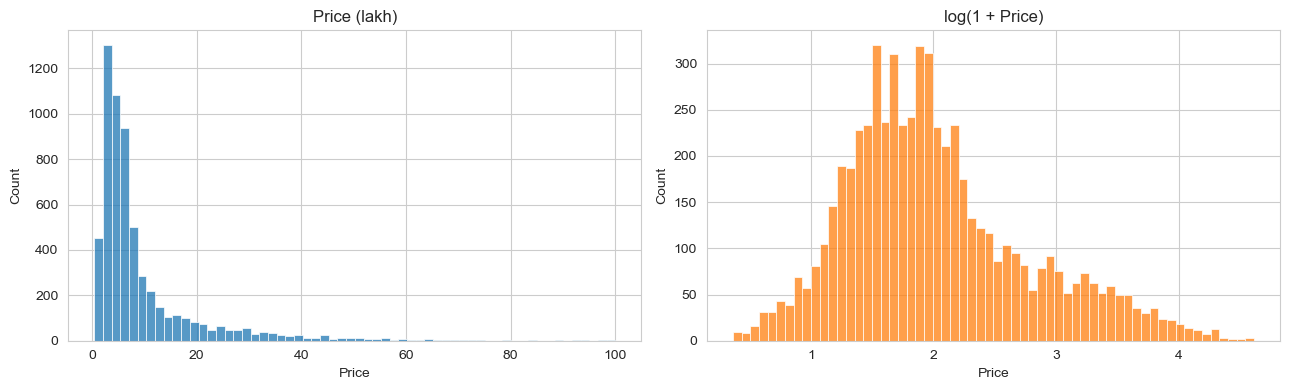

Skewness: price = 2.99, log(1 + price) = 0.74


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['Price'], bins=60, ax=axes[0])
axes[0].set_title('Price (lakh)')
sns.histplot(np.log1p(df['Price']), bins=60, ax=axes[1], color='tab:orange')
axes[1].set_title('log(1 + Price)')
plt.tight_layout(); plt.show()
print(f"Skewness: price = {df['Price'].skew():.2f}, log(1 + price) = {np.log1p(df['Price']).skew():.2f}")

The price has a **long right tail**: most cars cost a few lakh, a few cost 50–100.
Keep this in mind for step 9.

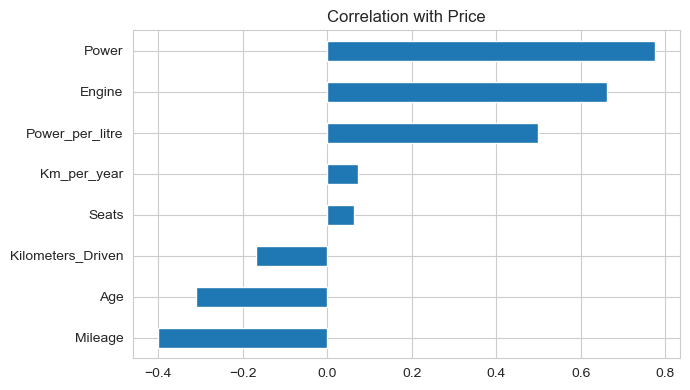

In [12]:
corr = add_features(df).corr(numeric_only=True)['Price'].drop('Price').sort_values()
corr.plot.barh(title='Correlation with Price', figsize=(7, 4), color='tab:blue')
plt.tight_layout(); plt.show()

`Power` and `Engine` matter most. `Seats` hardly relates to the price (≈ 0.06), so we leave it out, as in Data Preprocessing 08.

# 5. Train / test split
Split **first**, before anything learns from the data. The test set stays locked until the final evaluation.

In [13]:
X = df.drop(columns=[TARGET, 'Seats'])
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)
X_train.head()

Train: (4812, 11)  Test: (1203, 11)


,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Brand,Model
5642,Pune,2006,155000,Petrol,Manual,Third,15.400,"1,590.000",94.000,Maruti,Baleno
2303,Chennai,2006,109000,Petrol,Manual,First,16.900,"1,497.000",100.000,Honda,City
2618,Jaipur,2008,128813,Diesel,Manual,First,17.257,"1,396.000",69.000,Tata,Indigo
1397,Kochi,2016,35659,Diesel,Automatic,First,14.437,"2,993.000",258.000,BMW,X5
3704,Delhi,2013,51000,Diesel,Automatic,First,17.248,"1,582.000",126.320,Hyundai,Verna


# 6. The preprocessing pipeline
One small pipeline per column group, routed with a `ColumnTransformer`:

| Group | Columns | Steps |
|---|---|---|
| numeric | Kilometers_Driven, Mileage, Engine, Power, Age, Km_per_year, Power_per_litre | median imputer → outlier clipper (IQR) → polynomial features → MinMax scaler |
| nominal | Location, Fuel_Type, Transmission, Brand, Model | most-frequent imputer → binary encoder |
| ordinal | Owner_Type | most-frequent imputer → ordinal encoder (First < Second < Third < Fourth & Above) |

Every step that learns (medians, clip bounds, categories, min/max) learns from the **training data only**,
including inside each cross-validation fold.

In [14]:
numeric_cols = ['Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Age', 'Km_per_year', 'Power_per_litre']
nominal_cols = ['Location', 'Fuel_Type', 'Transmission', 'Brand', 'Model']
ordinal_cols = ['Owner_Type']
owner_type_categories = ['First', 'Second', 'Third', 'Fourth & Above']


def make_preprocessor(degree=1):
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('outlier_clipper', OutlierClipper(method='iqr')),
        ('poly_features', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scaler', MinMaxScaler()),
    ])
    nominal_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', BinaryEncoder()),
    ])
    ordinal_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(categories=[owner_type_categories])),
    ])
    return ColumnTransformer([
        ('num', numeric_pipeline, numeric_cols),
        ('nominal', nominal_pipeline, nominal_cols),
        ('ordinal', ordinal_pipeline, ordinal_cols),
    ], remainder='drop')


def make_pipeline(model, degree=1):
    """Raw car columns in, price out: feature engineering -> preprocessing -> model."""
    return Pipeline([
        ('features', FunctionTransformer(add_features)),   # ➕ feature engineering inside the pipeline
        ('preprocessor', make_preprocessor(degree)),
        ('model', model),
    ])


make_pipeline(LinearRegression())   # click the boxes to see each step

Pipeline(steps=[('features',
                 FunctionTransformer(func=<function add_features at 0x0000012C5A297D80>)),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('outlier_clipper',
                                                                   OutlierClipper()),
                                                                  ('poly_features',
                                                                   PolynomialFeatures(degree=1,
                                                                                      include_bias=False)),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['Kil...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   BinaryEncoder())]),
                                                  ['Location', 'Fuel_Type',
                                                   'Transmission', 'Brand',
                                                   'Model']),
                                                 ('ordinal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(categories=[['First',
                                                                                               'Second',
                                                                                               'Third',
                                                                                               'Fourth '
                                                                                               '& '
                                                                                               'Above']]))]),
                                                  ['Owner_Type'])])),
                ('model', LinearRegression())])

# 7. Baseline: Linear Regression
A simple model first, so we know what "better" means.

In [15]:
def evaluate(model, X, y):
    pred = model.predict(X)
    return {'R2': r2_score(y, pred),
            'MAE': mean_absolute_error(y, pred),
            'RMSE': root_mean_squared_error(y, pred),
            'Negative prices': int((pred < 0).sum())}

baseline = make_pipeline(LinearRegression(), degree=1).fit(X_train, y_train)
pd.DataFrame({'train': evaluate(baseline, X_train, y_train), 'test': evaluate(baseline, X_test, y_test)})

,train,test
R2,0.715,0.704
MAE,3.618,3.666
RMSE,5.846,5.826
Negative prices,478.000,124.000


R² ≈ 0.70: a straight line can't follow how price really moves with power and age.
And some predicted prices are **below zero**, which no car is worth.

# 8. Polynomial features + Ridge / Lasso, tuned with GridSearchCV
Three models, each with its own hyperparameters, all compared with **5-fold cross-validation on the training set**.
The pipeline step names give the parameter names: `preprocessor__num__poly_features__degree`, `model__alpha`.

In [16]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
degrees = [1, 2, 3, 4]

searches = {
    'Linear Regression': GridSearchCV(
        make_pipeline(LinearRegression()),
        {'preprocessor__num__poly_features__degree': degrees},
        cv=cv, scoring='r2', n_jobs=-1),
    'Ridge': GridSearchCV(
        make_pipeline(Ridge()),
        {'preprocessor__num__poly_features__degree': degrees,
         'model__alpha': [0.001, 0.01, 0.1, 1, 10]},
        cv=cv, scoring='r2', n_jobs=-1),
    'Lasso': GridSearchCV(
        make_pipeline(Lasso(max_iter=20_000)),     # more iterations: no ConvergenceWarning
        {'preprocessor__num__poly_features__degree': degrees,
         'model__alpha': [0.001, 0.01, 0.1, 1]},
        cv=cv, scoring='r2', n_jobs=-1),
}

for name, search in searches.items():
    search.fit(X_train, y_train)
    print(f'{name:18} CV R2 = {search.best_score_:.4f}   {search.best_params_}')

Linear Regression  CV R2 = 0.8472   {'preprocessor__num__poly_features__degree': 2}


Ridge              CV R2 = 0.8594   {'model__alpha': 0.1, 'preprocessor__num__poly_features__degree': 4}


Lasso              CV R2 = 0.8585   {'model__alpha': 0.001, 'preprocessor__num__poly_features__degree': 4}


In [17]:
cv_table = pd.DataFrame({name: {'CV R2': s.best_score_, **s.best_params_} for name, s in searches.items()}).T
cv_table.sort_values('CV R2', ascending=False)

,CV R2,preprocessor__num__poly_features__degree,model__alpha
Ridge,0.859,4.000,0.100
Lasso,0.859,4.000,0.001
Linear Regression,0.847,2.000,NaN


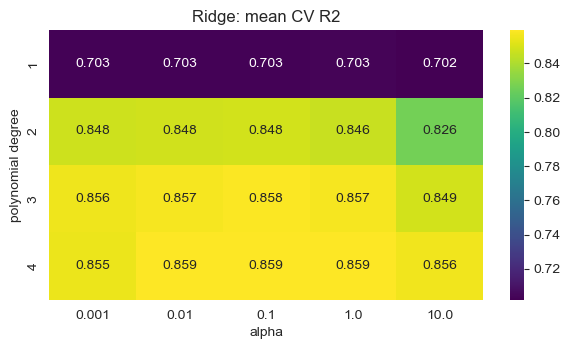

In [18]:
# How the degree and alpha interact for Ridge (mean CV R2)
ridge_results = pd.DataFrame(searches['Ridge'].cv_results_)
heat = ridge_results.pivot_table(index='param_preprocessor__num__poly_features__degree',
                                 columns='param_model__alpha', values='mean_test_score')
plt.figure(figsize=(7, 3.5))
sns.heatmap(heat, annot=True, fmt='.3f', cmap='viridis')
plt.title('Ridge: mean CV R2'); plt.xlabel('alpha'); plt.ylabel('polynomial degree')
plt.show()

In [19]:
best_name = cv_table['CV R2'].astype(float).idxmax()
course_model = searches[best_name].best_estimator_      # already refit on the whole training set
print('Best model from the course:', best_name, searches[best_name].best_params_)

Best model from the course: Ridge {'model__alpha': 0.1, 'preprocessor__num__poly_features__degree': 4}


# 9. ➕ Addition: predict log(price)
**Why:** the price has a long right tail (step 4). A model trained on raw prices pays most attention to the few
expensive cars, its errors grow with the price, and it can even predict negative prices.

**What we change:** train on `log(1 + price)` and turn the prediction back with `exp(·) − 1`.
`TransformedTargetRegressor` does both steps for us, so the saved model still takes a car and returns lakh.
Every predicted price is now positive by construction.

We tune it exactly like step 8 (same pipeline, same CV folds).
The alphas are smaller because the target is now on a log scale.

In [20]:
log_search = GridSearchCV(
    TransformedTargetRegressor(regressor=make_pipeline(Ridge()), func=np.log1p, inverse_func=np.expm1),
    {'regressor__preprocessor__num__poly_features__degree': degrees,
     'regressor__model__alpha': [0.01, 0.1, 1, 10]},
    cv=cv, scoring='r2', n_jobs=-1)
log_search.fit(X_train, y_train)
print(f'Ridge on log(price): CV R2 = {log_search.best_score_:.4f}   {log_search.best_params_}')
final_model = log_search.best_estimator_

Ridge on log(price): CV R2 = 0.8583   {'regressor__model__alpha': 1, 'regressor__preprocessor__num__poly_features__degree': 4}


# 10. Final evaluation on the test set
The test set was locked since step 5. We open it **once**, for the two finalists.

In [21]:
results = pd.DataFrame({
    'Baseline (Linear, degree 1)': evaluate(baseline, X_test, y_test),
    f'Course: {best_name}': evaluate(course_model, X_test, y_test),
    '➕ Final: Ridge on log(price)': evaluate(final_model, X_test, y_test),
}).T
results

,R2,MAE,RMSE,Negative prices
"Baseline (Linear, degree 1)",0.704,3.666,5.826,124.000
Course: Ridge,0.877,2.274,3.753,13.000
➕ Final: Ridge on log(price),0.862,1.934,3.976,0.000


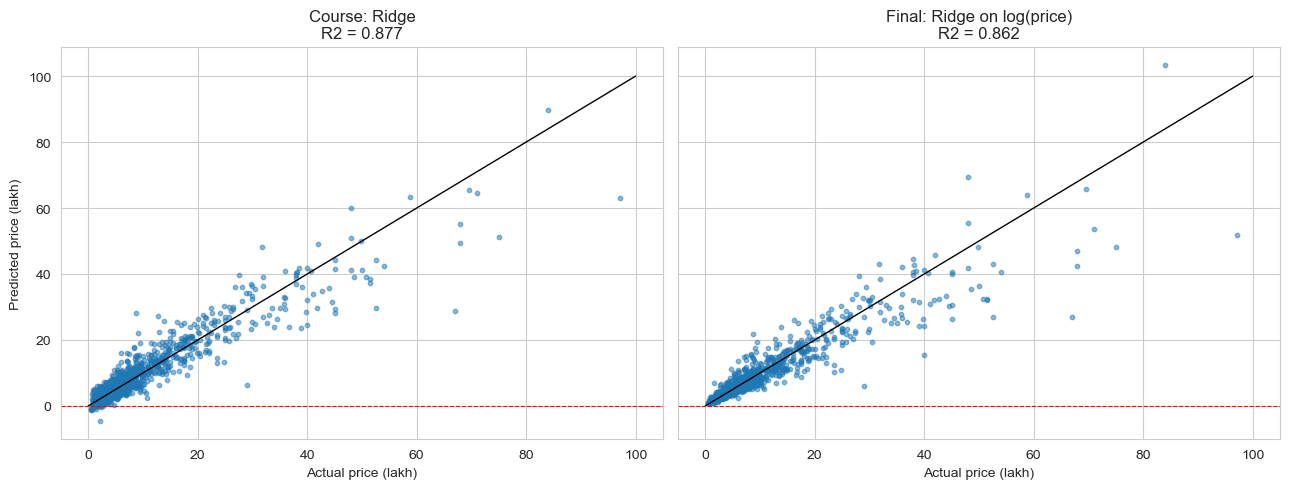

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, (title, model) in zip(axes, [(f'Course: {best_name}', course_model), ('Final: Ridge on log(price)', final_model)]):
    pred = model.predict(X_test)
    ax.scatter(y_test, pred, s=10, alpha=0.5)
    ax.plot([0, 100], [0, 100], color='black', lw=1)
    ax.axhline(0, color='red', lw=0.8, ls='--')
    ax.set_title(f'{title}\nR2 = {r2_score(y_test, pred):.3f}')
    ax.set_xlabel('Actual price (lakh)')
axes[0].set_ylabel('Predicted price (lakh)')
plt.tight_layout(); plt.show()

In [23]:
# Where does each model go wrong? Mean absolute error by price band
bands = pd.cut(y_test, [0, 5, 10, 20, 100], labels=['< 5', '5–10', '10–20', '20–100'])
by_band = pd.DataFrame({
    'cars': bands.value_counts().sort_index(),
    f'Course: {best_name}': (y_test - course_model.predict(X_test)).abs().groupby(bands, observed=True).mean(),
    'Final: log(price)': (y_test - final_model.predict(X_test)).abs().groupby(bands, observed=True).mean(),
})
by_band

,cars,Course: Ridge,Final: log(price)
Price,,,
< 5,525,1.254,0.645
5–10,379,2.007,1.485
10–20,170,2.799,2.555
20–100,129,6.521,7.681


**Which one do we ship?** Neither model wins on every number:

- ➕ Training on **log(price)** cuts the error on cheap cars by about half (the biggest group in the market),
  lowers the overall MAE, and never predicts a negative price.
- Training on the **raw price** keeps a higher R² and a lower RMSE. Both metrics square the errors,
  so they are driven by the few expensive cars, where the log model is less accurate.

Most sellers on the site have ordinary cars, so a smaller typical error (MAE) and no impossible prices matter more:
we ship the log model. Expensive cars stay the weak spot; models that handle them better (tree ensembles) come later in the course.

# 11. Save the model for the app
We save the **whole pipeline** (feature engineering + preprocessing + model) in one file.
The app also needs the dropdown choices (the brands and the models of each brand) and the input ranges seen in training.

In [24]:
models_dir = PROJECT / 'models'
models_dir.mkdir(exist_ok=True)
joblib.dump(final_model, models_dir / 'car_price_model.joblib')

train = X_train.assign(Price=y_train)
q = lambda col, lo=0.0, hi=1.0: [train[col].quantile(lo), train[col].quantile(hi)]
mode_car = train.loc[(train['Brand'] == 'Maruti') & (train['Model'] == 'Swift')].median(numeric_only=True)
test_mae = mean_absolute_error(y_test, final_model.predict(X_test))

app_options = {
    'input_columns': list(X_train.columns),
    'n_train': len(X_train),
    'test_mae': round(float(test_mae), 3),
    'locations': sorted(train['Location'].unique()),
    'fuel_types': sorted(train['Fuel_Type'].unique()),
    'transmissions': sorted(train['Transmission'].unique()),
    'owner_types': owner_type_categories,
    'brands': sorted(train['Brand'].unique()),
    'models_by_brand': {b: sorted(g['Model'].unique()) for b, g in train.groupby('Brand')},
    'ranges': {
        'Year': [int(train['Year'].min()), int(train['Year'].max())],
        'Kilometers_Driven': [int(round(train['Kilometers_Driven'].min(), -2)), int(round(train['Kilometers_Driven'].quantile(0.995), -3))],
        'Engine': [int(train['Engine'].min()), int(train['Engine'].max())],
        'Power': [float(np.floor(train['Power'].min())), float(np.ceil(train['Power'].max()))],
        'Mileage': [float(np.floor(train['Mileage'].min())), float(np.ceil(train['Mileage'].max()))],
    },
    'default': {'Brand': 'Maruti', 'Model': 'Swift', 'Location': 'Mumbai', 'Fuel_Type': 'Petrol',
                'Transmission': 'Manual', 'Year': 2015, 'Kilometers_Driven': 50_000,
                'Engine': int(mode_car['Engine']), 'Power': float(round(mode_car['Power'])),
                'Mileage': float(round(mode_car['Mileage'], 1))},
}
(models_dir / 'app_options.json').write_text(json.dumps(app_options, indent=2), encoding='utf-8')
print('Saved:', sorted(p.name for p in models_dir.iterdir()))

Saved: ['app_options.json', 'car_price_model.joblib', 'report.json']


In [25]:
# Numbers for the project page on the website
course_pred, final_pred = course_model.predict(X_test), final_model.predict(X_test)
report = {
    'n_raw': len(raw), 'n_clean': len(df), 'n_train': len(X_train), 'n_test': len(X_test),
    'cv': {name: {'r2': round(float(s.best_score_), 4),
                  'params': {k.split('__')[-1]: v for k, v in s.best_params_.items()}}
           for name, s in searches.items()},
    'cv_log': {'r2': round(float(log_search.best_score_), 4),
               'params': {k.split('__')[-1]: v for k, v in log_search.best_params_.items()}},
    'ridge_heat': {'degrees': [int(d) for d in heat.index], 'alphas': [float(a) for a in heat.columns],
                   'r2': heat.round(4).values.tolist()},
    'test': {k: {m: round(float(v), 4) for m, v in row.items()} for k, row in results.T.to_dict().items()},
    'best_name': best_name,
    'by_band': by_band.round(3).reset_index(names='band').to_dict(orient='list'),
    'scatter': {'actual': y_test.round(2).tolist(), 'course': np.round(course_pred, 2).tolist(),
                'final': np.round(final_pred, 2).tolist(),
                'brand': X_test['Brand'].tolist(), 'model': X_test['Model'].tolist(), 'year': X_test['Year'].tolist()},
}
(models_dir / 'report.json').write_text(json.dumps(report), encoding='utf-8')
print('Saved report.json')

Saved report.json


# 12. Use it: price a car that isn't in the data
This is exactly what the app does: one row of raw inputs → the saved pipeline → a price.

In [26]:
model = joblib.load(PROJECT / 'models' / 'car_price_model.joblib')

new_car = pd.DataFrame([{
    'Location': 'Pune', 'Year': 2016, 'Kilometers_Driven': 45_000, 'Fuel_Type': 'Diesel',
    'Transmission': 'Manual', 'Owner_Type': 'First', 'Mileage': 19.5, 'Engine': 1582,
    'Power': 126.2, 'Brand': 'Hyundai', 'Model': 'Creta',
}])
price = model.predict(new_car)[0]
print(f'Estimated price: ₹ {price:,.2f} lakh  (≈ ₹ {price * 100_000:,.0f})')

Estimated price: ₹ 10.99 lakh  (≈ ₹ 1,098,570)


# 📌 Takeaways
- **Diagnose before you clean**: a list of problems, then one fix per problem.
- **Fixed rules before the split, learned rules inside the pipeline**: no leakage, and the same steps run on new cars.
- Polynomial features let a linear model bend; **Ridge** keeps the extra weights in check. Tune degree and alpha **together** with cross-validation.
- ➕ A **skewed target** is easier on a log scale: better errors on cheap cars, and no negative prices.
- ➕ Put **feature engineering inside the pipeline**, so the app and the notebook can never disagree.
- Save the **whole pipeline**, not just the model.